# Assignment 2, Task 3a: VGG16 Classifier and Layer-wise Relevance Propagation

**Author:** Yeap Jie Shen (22062548)
**Course:** WQF7009 Explainable Artificial Intelligence, Assignment 2

**Objective:** train the brain tumour classifier of the provided `scripts/05_lrp.py` (deepfindr, 2021) and explain its predictions with Layer-wise Relevance Propagation (LRP; Bach et al., 2015).

**Approach:**
- Keep the provided model (ImageNet-pretrained VGG16, last layer replaced for four classes, Adam) and its LRP rules (Montavon et al., 2019).
- Fix the issues listed in [Section 2](#sec-changes) and train on the leak-free subsets of [notebook 04](04_mri_eda.ipynb#sec-subsets).
- Report results on the published test set and on a clean test set, and by scan type (CT vs MRI).
- The second method, Grad-CAM, and the comparison follow in [notebook 06](06_gradcam.ipynb).

**Contents**
1. [Setup](#sec-setup)
2. [Changes from `05_lrp.py`](#sec-changes)
3. [Training](#sec-training)
4. [Model performance](#sec-performance)
5. [LRP explainer](#sec-lrp)
6. [Sanity checks](#sec-checks)
7. [Local explanations](#sec-local)
8. [Class-contrastive explanation](#sec-contrast)
9. [Key takeaways](#sec-takeaways)
10. [References](#sec-references)

<a id="sec-setup"></a>

## 1. Setup

- Subsets from [notebook 04](04_mri_eda.ipynb#sec-subsets): train / validation / test.
- **Test sets:**
  - **Original:** all 394 published test images.
  - **Clean\*:** one image per near-identical group, and groups whose images carry different class labels left out.
- **Modality\*** (CT / MRI / Unclear) from `data/brain_mri_manual_labels.csv`; images not reviewed count as MRI.

\* Based on the author's visual judgement (not a radiologist), see [notebook 04](04_mri_eda.ipynb#sec-ct).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from captum.attr import LRP
from captum.attr._utils.lrp_rules import EpsilonRule, GammaRule
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader

from brain_mri_xai import SEED
from brain_mri_xai.data import (
    CLASS_LABELS,
    CLASSES,
    MRIDataset,
    annotate_test,
    flag_duplicates,
    index_images,
    load_images,
    normalise,
    split_train_validation,
)
from brain_mri_xai.explain import block_sums, lrp
from brain_mri_xai.model import (
    build_vgg16,
    device,
    load_model,
    median_confidence_case,
    predict_proba,
    randomise_top_layers,
    save_weights,
    seed_everything,
    train,
)
from brain_mri_xai.plotting import lrp_heatmap, show_image, show_lrp
from stroke_shap.plotting import COLORS, FIGURE_WIDTH, label_panels, save_figure, set_theme

set_theme()
LABELS = [CLASS_LABELS[c] for c in CLASSES]
index = flag_duplicates(index_images())
subsets = split_train_validation(index)
assert subsets["subset"].value_counts().to_dict() == {"train": 2161, "validation": 361, "test": 394}
images = {name: load_images(rows["path"]) for name, rows in subsets.groupby("subset")}
targets = {name: rows["target"].to_numpy() for name, rows in subsets.groupby("subset")}
test = annotate_test(index, subsets)
TEST_SETS = {"Original": test.index, "Clean*": test.index[test["clean"]]}
assert test["modality"].value_counts().to_dict() == {"MRI": 357, "CT": 36, "Unclear": 1}
assert len(TEST_SETS["Clean*"]) == len(test) - 101 - 2

<a id="sec-changes"></a>

## 2. Changes from `05_lrp.py`

Kept: the model, the optimiser, the learning rate and the LRP rule set. Changed, to fix errors or make results reproducible:

- **Test data:** the first `test_dataset` was built from `TRAIN_ROOT` → test images are read from `testing/` only.
- **Scoring:** a shuffled test loader scored one batch → the whole test set is scored once, in a fixed order.
- **Model selection:** no validation set, last epoch kept → grouped validation subset ([notebook 04](04_mri_eda.ipynb#sec-subsets)); epoch with the lowest validation loss kept.
- **Leakage:** training images that are near-copies of test images or of each other → dropped ([notebook 04](04_mri_eda.ipynb#sec-duplicates)).
- **Input scaling:** 255 x 255, no normalisation → 224 x 224; each image's 1st-99th grey-level percentile stretched to black-white (reduces the brightness shift of [notebook 04](04_mri_eda.ipynb#sec-sizes)), then ImageNet mean and standard deviation.
- **Augmentation:** none → horizontal flip, rotation (10°), shift (5%), zoom (10%).
- **Reproducibility:** no seeds, `cuda:0` hard-coded → `seed=2021` for Python, NumPy and PyTorch, deterministic cuDNN; GPU used if available.
- **Epochs:** 10 → 15, best epoch chosen on validation loss.
- **LRP:** top class only, LRP-gamma on the pixel layer → any class can be explained; $z^\mathcal{B}$ rule on the pixel layer.

<a id="sec-training"></a>

## 3. Training

- All VGG16 layers fine-tuned: Adam (`lr=1e-5`), cross-entropy loss, `batch_size=32`, `epochs=15`.
- Weights of the epoch with the lowest validation loss are kept and saved to `models/` (gitignored); [notebook 06](06_gradcam.ipynb) loads them.
- **Result:** lowest validation loss at epoch 13 (loss 0.093, accuracy 97.2%).

In [2]:
seed_everything()
loaders = {
    "train": DataLoader(
        MRIDataset(images["train"], targets["train"], augment=True),
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    ),
    "validation": DataLoader(MRIDataset(images["validation"], targets["validation"]), batch_size=64),
}
model, history = train(build_vgg16().to(device()), loaders["train"], loaders["validation"], epochs=15)
save_weights(model)
best = history.loc[history["validation_loss"].idxmin()]
history.set_index("epoch").rename_axis("Epoch").rename(
    columns=lambda c: c.replace("_", " ").capitalize()
).round(3)

,Train loss,Train accuracy,Validation loss,Validation accuracy
Epoch,,,,
1,0.989,0.577,0.480,0.812
2,0.449,0.826,0.310,0.892
3,0.340,0.873,0.260,0.900
4,0.282,0.894,0.292,0.903
5,0.214,0.920,0.207,0.922
6,0.181,0.930,0.174,0.939
7,0.149,0.943,0.155,0.947
8,0.120,0.954,0.138,0.945
9,0.093,0.967,0.110,0.970


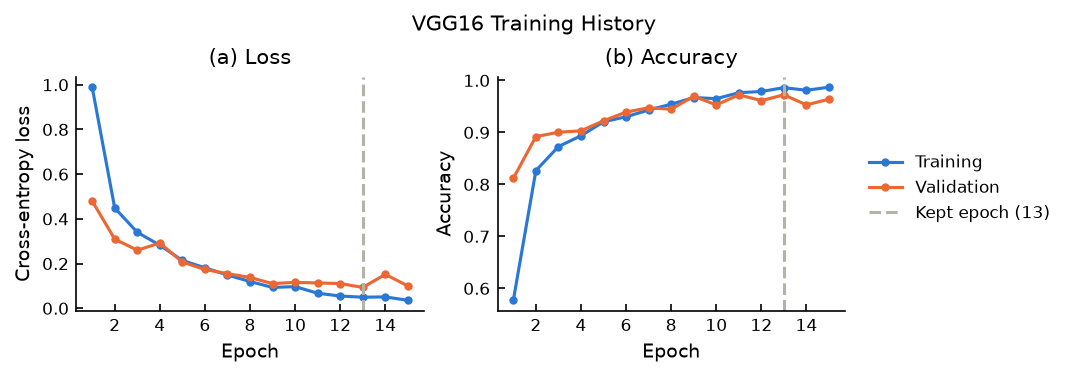

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 2.4))
for ax, metric, ylabel in [(axes[0], "loss", "Cross-entropy loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(history["epoch"], history[f"train_{metric}"], marker="o", markersize=3, label="Training")
    ax.plot(history["epoch"], history[f"validation_{metric}"], marker="o", markersize=3, label="Validation")
    ax.axvline(
        best["epoch"], color=COLORS["grey"], linestyle="--", label=f"Kept epoch ({int(best['epoch'])})"
    )
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel(ylabel)
axes[0].set_title("Loss")
axes[1].set_title("Accuracy")
label_panels(axes)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")
fig.suptitle("VGG16 Training History")
save_figure(fig, "05_training")

<a id="sec-performance"></a>

## 4. Model performance

- scikit-learn classification report on both test sets (Original, Clean\*; [Section 1](#sec-setup)).

- **Accuracy:** 56.6% on the Original test set, 58.1% on Clean\*, against 97.2% on validation ([Section 3](#sec-training)). Removing repeats barely changes the result, so the gap is not caused by them.
- **Errors go to No Tumour:** 41 of 100 gliomas, 46 of 115 meningiomas and 19 of 74 pituitary tumours are called No Tumour, so No Tumour has high recall (0.886) but low precision (0.467).
- **Tumour recall:** glioma 0.400, meningioma 0.530, pituitary 0.392. Glioma and Pituitary predictions are usually right (precision 0.769, 0.967); Meningioma predictions only about half the time (0.540).
- **Implication:** validation images come from the same folder, and so the same sources, as the training images; the test folder differs in size, brightness and scan type ([notebook 04](04_mri_eda.ipynb#sec-sizes)). Validation accuracy does not predict test accuracy.

In [4]:
model = load_model()  # the saved weights, as used by notebook 06
probabilities = predict_proba(model, images["test"])
test["predicted"] = probabilities.argmax(1)
test["confidence"] = probabilities.max(1)
test["correct"] = test["predicted"] == test["target"]
for name, rows in TEST_SETS.items():
    print(f"{name} test set ({len(rows)} images)")
    print(
        classification_report(
            test.loc[rows, "target"], test.loc[rows, "predicted"], target_names=LABELS, digits=3
        )
    )

Original test set (394 images)
              precision    recall  f1-score   support

      Glioma      0.769     0.400     0.526       100
  Meningioma      0.540     0.530     0.535       115
   No Tumour      0.467     0.886     0.612       105
   Pituitary      0.967     0.392     0.558        74

    accuracy                          0.566       394
   macro avg      0.686     0.552     0.558       394
weighted avg      0.659     0.566     0.558       394

Clean* test set (291 images)
              precision    recall  f1-score   support

      Glioma      0.791     0.420     0.548        81
  Meningioma      0.627     0.515     0.565       101
   No Tumour      0.453     0.893     0.601        75
   Pituitary      0.941     0.471     0.627        34

    accuracy                          0.581       291
   macro avg      0.703     0.575     0.585       291
weighted avg      0.664     0.581     0.577       291



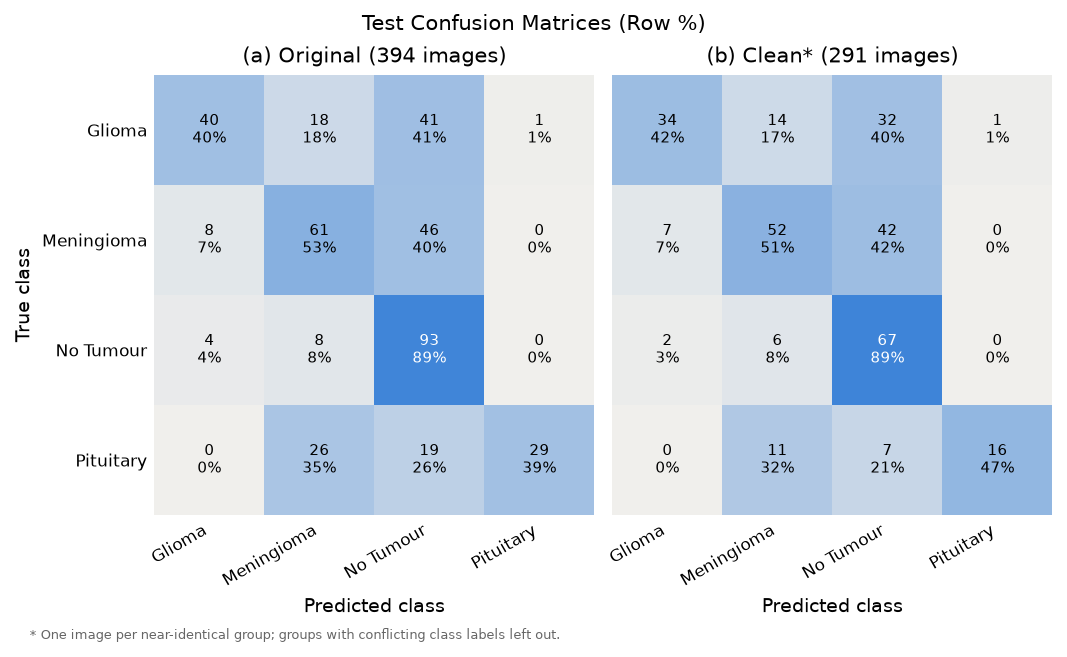

In [5]:
cmap = LinearSegmentedColormap.from_list("blues", ["#f0efec", COLORS["blue"]])
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, FIGURE_WIDTH * 0.61))
for ax, (name, rows) in zip(axes, TEST_SETS.items(), strict=True):
    matrix = confusion_matrix(
        test.loc[rows, "target"], test.loc[rows, "predicted"], labels=range(len(CLASSES))
    )
    row_share = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(row_share, cmap=cmap, vmin=0, vmax=1)
    for (i, j), n in np.ndenumerate(matrix):
        ax.text(
            j,
            i,
            f"{n}\n{row_share[i, j]:.0%}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if row_share[i, j] > 0.6 else "black",
        )
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=30, ha="right")
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set_xlabel("Predicted class")
    ax.set_title(f"{name} ({len(rows)} images)")
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0)
axes[0].set_ylabel("True class")
axes[1].tick_params(labelleft=False)
label_panels(axes)
fig.suptitle("Test Confusion Matrices (Row %)")
fig.supxlabel(
    "* One image per near-identical group; groups with conflicting class labels left out.",
    x=0.02,
    ha="left",
    fontsize=6,
    color="0.4",
)
save_figure(fig, "05_confusion")

<a id="sec-normalisation"></a>

### 4.1 Brightness normalisation check

- Same split, seed and training, but without the per-image brightness stretch ([Section 2](#sec-changes)); this second model is used only here and is not saved.

- **Result:** with the brightness stretch, accuracy is 2.0 percentage points higher on Original (56.6% vs 54.6%) and 1.1 on Clean\* (58.1% vs 57.0%), fewer tumours are missed (106 vs 125 of 289), fewer false alarms are raised (12 vs 19 of 105) and more CT\* images are right (27 vs 21 of 36).
- **Implication:** the normalisation is kept. It helps, but does not close the gap to validation, so the main cause lies elsewhere: the two folders differ in more than brightness (size, sequence, CT; [notebook 04](04_mri_eda.ipynb#sec-sizes)), and, with the leak removed, test images no longer have near-copies in training ([notebook 04](04_mri_eda.ipynb#sec-duplicates)).

In [6]:
seed_everything()
plain_model, _ = train(
    build_vgg16().to(device()),
    DataLoader(
        MRIDataset(images["train"], targets["train"], augment=True, per_image=False),
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    ),
    DataLoader(MRIDataset(images["validation"], targets["validation"], per_image=False), batch_size=64),
    epochs=15,
)
plain_predicted = predict_proba(plain_model, images["test"], per_image=False).argmax(1)
del plain_model
torch.cuda.empty_cache()

no_tumour = CLASSES.index("no_tumor")
tumour, ct = test["target"] != no_tumour, test["modality"] == "CT"
normalisation = {}
for name, predicted in {"With (kept)": test["predicted"], "Without": plain_predicted}.items():
    correct = predicted == test["target"]
    normalisation[name] = {
        "Accuracy, Original": f"{correct.mean():.1%}",
        "Accuracy, Clean*": f"{correct[test['clean']].mean():.1%}",
        "Missed tumours, Original": f"{(tumour & (predicted == no_tumour)).sum()}/{tumour.sum()}",
        "False alarms, Original": f"{(~tumour & (predicted != no_tumour)).sum()}/{(~tumour).sum()}",
        "Accuracy on CT*": f"{correct[ct].sum()}/{ct.sum()} ({correct[ct].mean():.1%})",
    }
pd.DataFrame(normalisation).rename_axis("Brightness normalisation", axis=1)

Brightness normalisation,With (kept),Without
"Accuracy, Original",56.6%,54.6%
"Accuracy, Clean*",58.1%,57.0%
"Missed tumours, Original",106/289,125/289
"False alarms, Original",12/105,19/105
Accuracy on CT*,27/36 (75.0%),21/36 (58.3%)


<a id="sec-modality"></a>

### 4.2 CT vs MRI

- Recall per modality\* and true class (share of each class's images predicted correctly), on both test sets.

- **CT\*:** No Tumour recall 85.7% (24 of 28 CT scans), but all 3 CT gliomas are wrong; training contains no CT tumour other than 5 meningiomas.
- **MRI\*:** recall No Tumour 89.6%, tumour classes 39.2-52.3%. The tumour problem is not limited to CT.
- **Clean\*:** same pattern (MRI recall No Tumour 92.7%, tumour classes 43.6-50.5%).

In [7]:
by_modality = pd.concat(
    {
        name: test.loc[rows]
        .groupby(["modality", test.loc[rows, "label"].map(CLASS_LABELS)])["correct"]
        .agg(Images="size", Correct="sum", Recall="mean")
        for name, rows in TEST_SETS.items()
    },
    axis=1,
)
by_modality.rename_axis(["Modality*", "True class"]).style.format(
    {(name, "Recall"): "{:.1%}" for name in TEST_SETS}
    | {(n, c): "{:.0f}" for n in TEST_SETS for c in ["Images", "Correct"]},
    na_rep="-",
)

<a id="sec-errors"></a>

### 4.3 Clinical consequences of errors

Errors grouped by what they would mean for a patient, taking "tumour vs no tumour" as the screening question:

- **Missed tumour** (false negative): tumour scan predicted No Tumour → delayed diagnosis and treatment; the patient is falsely reassured.
- **False alarm** (false positive): No Tumour scan predicted as a tumour → anxiety, extra imaging or referral.
- **Wrong tumour type:** tumour predicted as another tumour type → wrong urgency or treatment pathway, e.g. a glioma, often fast-growing and infiltrating, handled as a meningioma, mostly slow-growing and benign (Louis et al., 2021).

- **Result:** 106 of 289 tumours are missed (36.7%), 12 of 105 No Tumour scans are flagged (11.4%) and 53 of 289 tumours get the wrong type (18.3%); Clean\* rates are similar (37.5%, 10.7%, 15.3%).
- **Implication:** the dominant error is the most harmful one. As a screening tool, the model would falsely reassure on more than a third of tumour scans.

In [8]:
rates = {}
for name, rows in TEST_SETS.items():
    true, predicted = test.loc[rows, "target"], test.loc[rows, "predicted"]
    tumour = true != no_tumour
    errors = {
        "Missed tumour": ((tumour & (predicted == no_tumour)).sum(), tumour.sum()),
        "False alarm": ((~tumour & (predicted != no_tumour)).sum(), (~tumour).sum()),
        "Wrong tumour type": ((tumour & (predicted != no_tumour) & (predicted != true)).sum(), tumour.sum()),
    }
    rates[name] = {error: f"{n}/{total} ({n / total:.1%})" for error, (n, total) in errors.items()}
pd.DataFrame(rates).rename_axis("Error")

,Original,Clean*
Error,,
Missed tumour,106/289 (36.7%),81/216 (37.5%)
False alarm,12/105 (11.4%),8/75 (10.7%)
Wrong tumour type,53/289 (18.3%),33/216 (15.3%)


<a id="sec-uncertainty"></a>

### 4.4 Confidence and uncertainty

- Confidence = the top softmax probability; Original test set, three confidence bands.

- **Result:** 68% of the 171 errors have confidence below 90%; in that band, accuracy is 41.4%. Above 90%, accuracy is 75.0% (90-99%) and 69.4% (99% and above): the most confident band still holds 33 errors.
- **Implication:** low confidence is a useful warning, but high confidence is not a guarantee; confidence is not the probability of being right (Guo et al., 2017).

In [9]:
test["band"] = pd.cut(
    test["confidence"],
    [0, 0.9, 0.99, 1],
    labels=["Below 90%", "90-99%", "99% and above"],
    include_lowest=True,
)
bands = test.groupby("band", observed=False).agg(
    images=("correct", "size"), errors=("correct", lambda c: (~c).sum()), accuracy=("correct", "mean")
)
bands["share of all errors"] = bands["errors"] / bands["errors"].sum()
bands.loc["All", ["images", "errors", "accuracy"]] = [
    len(test),
    (~test["correct"]).sum(),
    test["correct"].mean(),
]
bands.rename_axis("Confidence").rename(columns=str.capitalize).style.format(
    {"Images": "{:.0f}", "Errors": "{:.0f}", "Accuracy": "{:.1%}", "Share of all errors": "{:.0%}"}, na_rep=""
)

,Images,Errors,Accuracy,Share of all errors
Confidence,,,,
Below 90%,198,116,41.4%,68%
90-99%,88,22,75.0%,13%
99% and above,108,33,69.4%,19%
All,394,171,56.6%,


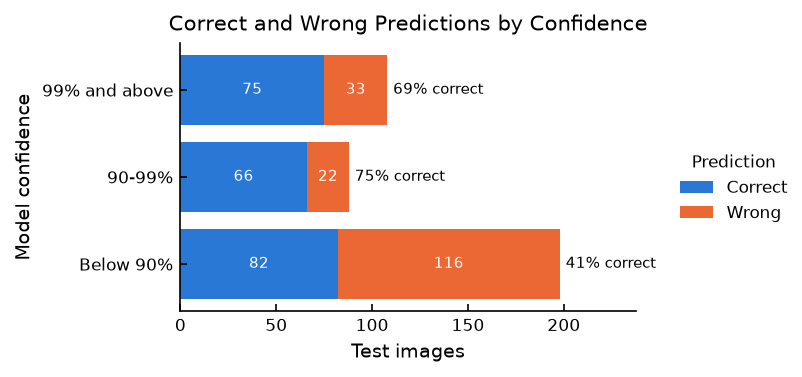

In [10]:
counts = pd.crosstab(test["band"], test["correct"].map({True: "Correct", False: "Wrong"}))
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 2.4))
left = np.zeros(len(counts))
for label, color in [("Correct", COLORS["blue"]), ("Wrong", COLORS["orange"])]:
    bars = ax.barh(counts.index.astype(str), counts[label], left=left, color=color, label=label)
    ax.bar_label(bars, label_type="center", fontsize=7, color="white")
    left += counts[label].to_numpy()
for y, (total, accuracy) in enumerate(zip(left, bands["accuracy"].iloc[:3], strict=True)):
    ax.text(total + 3, y, f"{accuracy:.0%} correct", va="center", fontsize=7)
ax.set_xlim(0, left.max() * 1.2)
ax.set_xlabel("Test images")
ax.set_ylabel("Model confidence")
ax.set_title("Correct and Wrong Predictions by Confidence")
fig.legend(loc="outside right center", title="Prediction")
save_figure(fig, "05_confidence")

<a id="sec-lrp"></a>

## 5. LRP explainer

- LRP passes the logit of the explained class backwards, layer by layer, to the input pixels.
- Each neuron hands its relevance to the neurons below in proportion to their contribution $a_j w_{jk}$, so the basic rule (LRP-0) conserves relevance from layer to layer; LRP-$\epsilon$ and the biases absorb part of it ([Section 6](#sec-checks)).
- Different rules suit different depths (Montavon et al., 2019):

| Layer index | VGG16 layers | Rule | Purpose |
|---|---|---|---|
| 0 | conv1_1 (pixels) | $z^\mathcal{B}$ | Uses the known pixel range (black to white) as bounds |
| 1-16 | conv1_2 to conv3_3 | LRP-$\gamma$ (`gamma=0.25`) | Favours positive contributions; less noisy low-level maps |
| 17-30 | conv4_1 to conv5_3 | LRP-$\epsilon$ ($\epsilon$ = 0.25 x RMS) | Absorbs weak, contradictory contributions; keeps salient paths |
| 31-37 | Dense layers (as convolutions) | LRP-0 | Basic rule; few top layers, close to the output |

- **Output:** one relevance value per pixel, summed over the three colour channels; red = evidence **for** the explained class, blue = evidence **against** it.

<a id="sec-checks"></a>

## 6. Sanity checks

Three checks on 40 test images drawn with `seed=2021`, each explained for its predicted class:

1. **Conservation:** pixel relevances should add up to a stable, positive share of the explained logit; below 1 by design, as LRP-$\epsilon$ and the biases absorb part of the relevance.
2. **Agreement with Captum** (Kokhlikyan et al., 2020): an independent LRP implementation with the closest rules it offers (LRP-$\gamma$, then a fixed $\epsilon$). It has no $z^\mathcal{B}$ rule and routes relevance through max pooling to the maximum only, so agreement is measured on 16 x 16-pixel blocks (Spearman rank correlation).
3. **Model randomisation** (Adebayo et al., 2018): the dense layers and the last convolutional block are re-initialised. A map that reflects the trained model should change a lot (low rank correlation with the original map); one that only traces image edges barely changes.

- **Conservation:** on average 15.3% of the explained logit reaches the pixels (median 15.0%, range 3.5-22.5%); stable and positive, but most relevance is absorbed by LRP-$\epsilon$ and the biases, so the map shows where relevance goes, not a full split of the logit.
- **Captum:** median block-level rank correlation 0.553 (range 0.128-0.761): agreement on the broad layout, not the detail, as expected from the different rules.
- **Randomisation:** after conv5 and the dense layers are re-initialised, the maps keep a median rank correlation of 0.690 with the originals. LRP fails this check: its maps partly show image structure (edges, the skull outline), a known weakness of rule sets that favour positive contributions (Sixt et al., 2020). [Notebook 06](06_gradcam.ipynb#sec-gradcam) repeats the check for Grad-CAM.
- **Cost:** median 0.360 s per image on the GPU (40 check images).

In [11]:
def captum_lrp(model: torch.nn.Module, image: torch.Tensor, target: int) -> np.ndarray:
    """Captum LRP heatmap (summed over channels) with the closest rule set to :func:`lrp`."""
    for i, layer in enumerate(model.features):
        if isinstance(layer, torch.nn.Conv2d):
            layer.rule = GammaRule(gamma=0.25) if i <= 16 else EpsilonRule(epsilon=0.25)
    relevance = LRP(model).attribute(image.unsqueeze(0).to(device()), target=target)
    return relevance[0].sum(0).detach().cpu().numpy()


N_CHECK = 40
check_ids = np.random.default_rng(SEED).choice(len(test), size=N_CHECK, replace=False)
random_model = randomise_top_layers(load_model())
checks = []
for i in check_ids:
    image, target = normalise(images["test"][i]), int(test.loc[i, "predicted"])
    start = time.perf_counter()
    relevance = lrp(model, image, target)
    seconds = time.perf_counter() - start
    with torch.no_grad():
        logit = model(image.unsqueeze(0).to(device()))[0, target].item()
    ours = lrp_heatmap(relevance)
    theirs = captum_lrp(load_model(), image, target)  # fresh copy: Captum adds hooks and rules
    randomised = lrp_heatmap(lrp(random_model, image, target))
    checks.append(
        (
            relevance.sum().item() / logit,
            spearmanr(block_sums(ours), block_sums(theirs))[0],
            spearmanr(block_sums(np.abs(ours)), block_sums(np.abs(randomised)))[0],
            seconds,
        )
    )
checks = pd.DataFrame(
    checks,
    columns=[
        "Relevance sum / logit",
        "Rank correlation with Captum",
        "Rank correlation after randomisation",
        "Seconds per image",
    ],
)
checks.describe().loc[["mean", "50%", "min", "max"]].rename(index={"50%": "median"}).round(3).T

c:\Users\yeapj\miniconda3\envs\wqf7009_assignments\Lib\site-packages\captum\attr\_core\lrp.py:207: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(input_tuple)


,mean,median,min,max
Relevance sum / logit,0.153,0.150,0.035,0.225
Rank correlation with Captum,0.532,0.553,0.128,0.761
Rank correlation after randomisation,0.648,0.690,0.361,0.854
Seconds per image,0.375,0.360,0.344,0.577


<a id="sec-local"></a>

## 7. Local explanations

- **Case selection:** per class, the correctly classified Clean\* MRI\* test image with the median confidence among those images (a typical, not a best-case, example); CT scans are left out, as the model may separate them by scan type ([Section 4.2](#sec-modality)).
- Images are identified by their file name in `data/brain_mri/testing/`.
- Reading of the heatmaps below is the author's visual judgement (not a radiologist).

- **Glioma** (`glioma_tumor/image(74).jpg`, 98.6%): red on the enhancing lesion, but the skull ring is just as red.
- **Meningioma** (`meningioma_tumor/image(88).jpg`, 94.3%): strongest red along the lower edge of the large bright tumour, plus a red spot on a ventricle.
- **No Tumour** (`no_tumor/image(29).jpg`, 99.1%): red spread over the whole brain, strongest at the front; no single structure, consistent with a judgement about the overall appearance.
- **Pituitary** (`pituitary_tumor/image(94).jpg`, 95.2%): the tumour itself is mostly white (neutral); red lies below it and on scattered tissue. A correct answer without clear evidence on the tumour.
- **Artefact:** a thin red frame along the image border appears in every map; it comes from the zero padding of the first convolutions, not from the scan.

In [12]:
candidates = test[test["correct"] & test["clean"] & (test["modality"] == "MRI")]
cases = {label: median_confidence_case(candidates[candidates["label"] == label]) for label in CLASSES}
case_table = test.loc[list(cases.values()), ["label", "path", "confidence"]].assign(
    label=lambda d: d["label"].map(CLASS_LABELS),
    path=lambda d: d["path"].map(lambda p: f"{p.parent.name}/{p.name}"),
)
case_table.rename(columns={"label": "Class", "path": "File", "confidence": "Confidence"}).set_index(
    "Class"
).round(3)

,File,Confidence
Class,,
Glioma,glioma_tumor/image(74).jpg,0.986
Meningioma,meningioma_tumor/image(88).jpg,0.943
No Tumour,no_tumor/image(29).jpg,0.991
Pituitary,pituitary_tumor/image(94).jpg,0.952


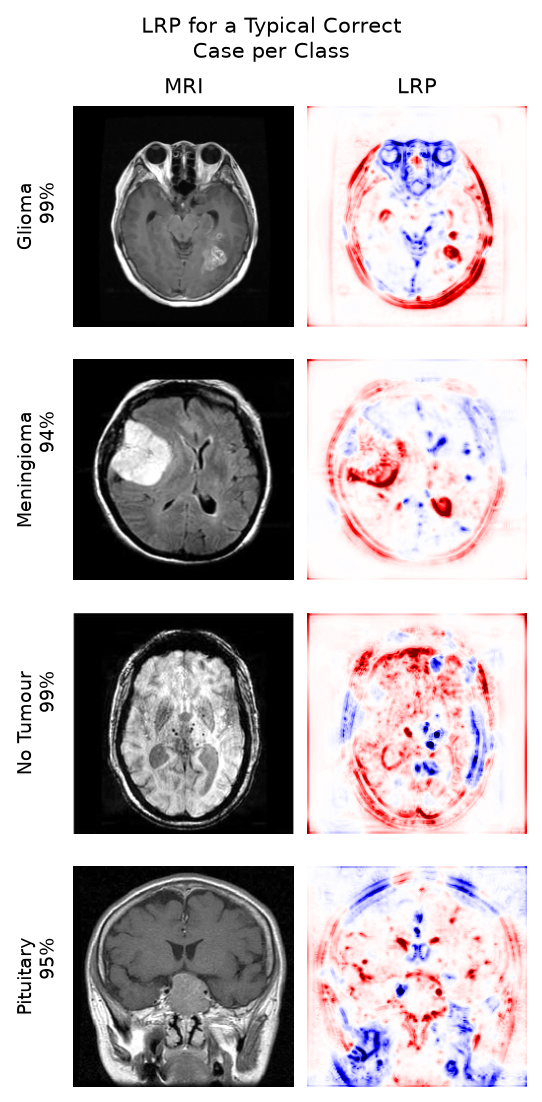

In [13]:
fig, axes = plt.subplots(len(CLASSES), 2, figsize=(FIGURE_WIDTH * 0.5, FIGURE_WIDTH + 0.3))
for row, (label, i) in zip(axes, cases.items(), strict=True):
    image = normalise(images["test"][i])
    show_image(row[0], image)
    show_lrp(row[1], lrp_heatmap(lrp(model, image, int(test.loc[i, "predicted"]))))
    row[0].text(
        -0.06,
        0.5,
        f"{CLASS_LABELS[label]}\n{test.loc[i, 'confidence']:.0%}",
        transform=row[0].transAxes,
        rotation=90,
        ha="right",
        va="center",
    )
axes[0, 0].set_title("MRI")
axes[0, 1].set_title("LRP")
fig.suptitle("LRP for a Typical Correct\nCase per Class")
save_figure(fig, "05_lrp_cases")

<a id="sec-contrast"></a>

## 8. Class-contrastive explanation

- LRP explains one class at a time, so one scan can be explained for the predicted class and for the runner-up.
- Where the two maps differ shows what separates the two diagnoses in the model's view.

- **Main case:** `meningioma_tumor/image(88).jpg`, chosen by the case rule of [Section 7](#sec-local); the tumour is large and clearly visible, so the explanation can be checked by eye. It is reused in [notebook 06](06_gradcam.ipynb#sec-main) and the slides.
- **Result:** Meningioma 94.3%, runner-up No Tumour 5.6%. The tumour edge that is red for Meningioma (b) is blue for No Tumour (c), and so is the ventricle spot.
- **Implication:** the decision between the two diagnoses rests on the tumour boundary; the same pixels count for one class and against the other.

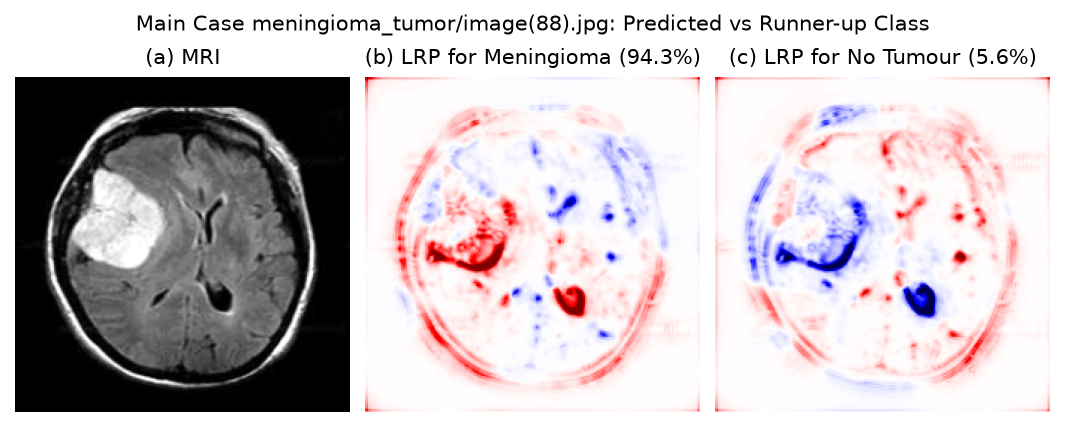

In [14]:
MAIN_CLASS = "meningioma_tumor"
main = cases[MAIN_CLASS]
image = normalise(images["test"][main])
ranked = probabilities[main].argsort()[::-1]
fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH, FIGURE_WIDTH / 3 + 0.4))
show_image(axes[0], image)
axes[0].set_title("MRI")
for ax, target in zip(axes[1:], ranked[:2], strict=True):
    show_lrp(ax, lrp_heatmap(lrp(model, image, int(target))))
    ax.set_title(f"LRP for {LABELS[target]} ({probabilities[main, target]:.1%})")
label_panels(axes)
main_file = f"{test.loc[main, 'path'].parent.name}/{test.loc[main, 'path'].name}"
fig.suptitle(f"Main Case {main_file}: Predicted vs Runner-up Class")
save_figure(fig, "05_lrp_contrast")

<a id="sec-takeaways"></a>

## 9. Key takeaways

1. **Validation overstates performance** ([Section 4](#sec-performance)): 97.2% on validation, 56.6% on the Original test set, 58.1% on Clean\*.
2. **The main error is a missed tumour** ([Section 4.3](#sec-errors)): 106 of 289 tumours (36.7%) are called No Tumour; on MRI\* as well as CT\* ([Section 4.2](#sec-modality)).
3. **Brightness normalisation helps a little** ([Section 4.1](#sec-normalisation)): +2.0 percentage points accuracy (Original), 19 fewer missed tumours; the gap to validation remains.
4. **High confidence is no guarantee** ([Section 4.4](#sec-uncertainty)): 33 errors at 99% confidence or more.
5. **LRP finds clear lesions** ([Section 7](#sec-local)): the glioma and the meningioma edge, but also the skull ring; the pituitary tumour is not marked.
6. **LRP is partly image-driven** ([Section 6](#sec-checks)): rank correlation 0.690 after randomisation, so a second method is needed ([notebook 06](06_gradcam.ipynb)).
7. **Class-contrastive maps help** ([Section 8](#sec-contrast)): for the main case, the tumour edge supports Meningioma and counts against No Tumour.

<a id="sec-references"></a>

## 10. References

Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M., & Kim, B. (2018). Sanity checks for saliency maps. *Advances in Neural Information Processing Systems, 31*, 9505-9515. https://doi.org/10.48550/arXiv.1810.03292

Bach, S., Binder, A., Montavon, G., Klauschen, F., Müller, K.-R., & Samek, W. (2015). On pixel-wise explanations for non-linear classifier decisions by layer-wise relevance propagation. *PLOS ONE, 10*(7), e0130140. https://doi.org/10.1371/journal.pone.0130140

deepfindr. (2021). *xai-series* [Computer software]. GitHub. https://github.com/deepfindr/xai-series

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of the 34th International Conference on Machine Learning, PMLR 70*, 1321-1330. https://proceedings.mlr.press/v70/guo17a.html

Kokhlikyan, N., Miglani, V., Martin, M., Wang, E., Alsallakh, B., Reynolds, J., Melnikov, A., Kliushkina, N., Araya, C., Yan, S., & Reblitz-Richardson, O. (2020). *Captum: A unified and generic model interpretability library for PyTorch*. arXiv. https://doi.org/10.48550/arXiv.2009.07896

Louis, D. N., Perry, A., Wesseling, P., Brat, D. J., Cree, I. A., Figarella-Branger, D., Hawkins, C., Ng, H. K., Pfister, S. M., Reifenberger, G., Soffietti, R., von Deimling, A., & Ellison, D. W. (2021). The 2021 WHO classification of tumors of the central nervous system: A summary. *Neuro-Oncology, 23*(8), 1231-1251. https://doi.org/10.1093/neuonc/noab106

Montavon, G., Binder, A., Lapuschkin, S., Samek, W., & Müller, K.-R. (2019). Layer-wise relevance propagation: An overview. In W. Samek, G. Montavon, A. Vedaldi, L. K. Hansen, & K.-R. Müller (Eds.), *Explainable AI: Interpreting, explaining and visualizing deep learning* (pp. 193-209). Springer. https://doi.org/10.1007/978-3-030-28954-6_10

Sixt, L., Granz, M., & Landgraf, T. (2020). When explanations lie: Why many modified BP attributions fail. *Proceedings of the 37th International Conference on Machine Learning, PMLR 119*, 9046-9057. https://proceedings.mlr.press/v119/sixt20a.html